# Phase 03 — Psychological Capital → Employability

## Step 09 — Explainable AI using SHAP

මෙම notebook එකේ අරමුණ Step 08 එකේ තෝරාගත් සහ save කරන ලද final ElasticNet model එක Explainable AI methods භාවිත කර interpret කිරීමයි.

මෙම step එකේ model එක නැවත train නොකරයි.

Step 08 එකේ save කරන ලද exact fitted pipeline එක load කර පහත explainability methods භාවිත කරයි:

1. SHAP global feature importance
2. SHAP local prediction explanations
3. ElasticNet standardized coefficient interpretation
4. Permutation importance
5. Explainability-method consistency analysis

මෙම analysis එක Psychological Capital constructs model prediction එකට කොපමණ සහ කුමන direction එකෙන් contribute කරනවද යන්න තේරුම් ගැනීමට සහ Step 10 recommendation system එක සඳහා evidence ලබාදීමට භාවිත කරයි.

SHAP values model behaviour explain කරන අතර causal relationships prove නොකරයි.

In [1]:
from pathlib import Path

import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.inspection import (
    permutation_importance
)

d:\internship-employability-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

MODEL_DIR = (
    PROJECT_DIR
    / "models"
    / "phase3"
)

MODEL_PATH = (
    MODEL_DIR
    / "phase3_psycap_selected_model.pkl"
)

METADATA_PATH = (
    MODEL_DIR
    / "phase3_psycap_model_metadata.json"
)

FEATURE_SCHEMA_PATH = (
    MODEL_DIR
    / "phase3_psycap_feature_schema.json"
)

REFERENCE_PATH = (
    MODEL_DIR
    / "phase3_psycap_reference_predictions.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "shap_explainability"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("MODEL_PATH:", MODEL_PATH)
print("REPORT_DIR:", REPORT_DIR)

MODEL_PATH: d:\internship-employability-project\models\phase3\phase3_psycap_selected_model.pkl
REPORT_DIR: d:\internship-employability-project\reports\phase3\shap_explainability


Check Step 08 artifacts

In [3]:
required_artifacts = {
    "Final Model": MODEL_PATH,
    "Metadata": METADATA_PATH,
    "Feature Schema": FEATURE_SCHEMA_PATH,
    "Reference Predictions": REFERENCE_PATH
}

artifact_check = []

for name, path in required_artifacts.items():

    artifact_check.append({
        "Artifact": name,
        "Path": str(path),
        "Exists": path.exists()
    })

artifact_check_df = pd.DataFrame(
    artifact_check
)

artifact_check_df

,Artifact,Path,Exists
0,Final Model,d:\internship-employability-project\models\pha...,True
1,Metadata,d:\internship-employability-project\models\pha...,True
2,Feature Schema,d:\internship-employability-project\models\pha...,True
3,Reference Predictions,d:\internship-employability-project\models\pha...,True


Load metadata and feature schema

In [4]:
with open(
    METADATA_PATH,
    "r",
    encoding="utf-8"
) as file:

    metadata = json.load(
        file
    )


with open(
    FEATURE_SCHEMA_PATH,
    "r",
    encoding="utf-8"
) as file:

    feature_schema = json.load(
        file
    )


print(
    "Saved model name:",
    metadata["model_name"]
)

print(
    "Saved features:",
    feature_schema["features"]
)

Saved model name: ElasticNet
Saved features: ['Hope_avg', 'Optimism_avg', 'Resilience_avg', 'SelfEfficacy_avg']


Load exact final model

In [5]:
final_model = joblib.load(
    MODEL_PATH
)

print(
    final_model
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 ElasticNet(alpha=np.float64(0.14873521072935117), l1_ratio=0.0,
                            max_iter=50000, random_state=42))])


## Exact Saved Model Verification

Explainability analysis එක Step 08 එකේ final model selection සඳහා භාවිත කළ exact persisted pipeline එක මත පදනම් වේ.

Model එක Step 09 එකේ නැවත fit නොකරන අතර saved preprocessing සහ model parameters unchanged ලෙස භාවිත කරයි.

Verify model hash

In [6]:
def calculate_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as file:

        for block in iter(
            lambda: file.read(4096),
            b""
        ):

            sha256.update(
                block
            )

    return sha256.hexdigest()


current_model_hash = calculate_sha256(
    MODEL_PATH
)

saved_model_hash = metadata[
    "model_sha256"
]

print(
    "Saved hash:",
    saved_model_hash
)

print(
    "Current hash:",
    current_model_hash
)

print(
    "Hash matches:",
    current_model_hash
    ==
    saved_model_hash
)

Saved hash: 6d8ed0af743a35f91dccf7f85630056d5a9afb551f2b887b3ff5f4daca5aa75b
Current hash: 6d8ed0af743a35f91dccf7f85630056d5a9afb551f2b887b3ff5f4daca5aa75b
Hash matches: True


Load dataset

In [7]:
df = pd.read_csv(
    DATA_PATH
)

FEATURES = feature_schema[
    "features"
]

TARGET = feature_schema[
    "target"
]

X = df[
    FEATURES
].copy()

y = df[
    TARGET
].copy()

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

X shape: (1000, 4)
y shape: (1000,)


Verify feature order

In [8]:
print(
    "Expected feature order:",
    FEATURES
)

print(
    "Actual feature order:",
    X.columns.tolist()
)

feature_order_valid = (
    X.columns.tolist()
    ==
    FEATURES
)

print(
    "Feature order valid:",
    feature_order_valid
)

Expected feature order: ['Hope_avg', 'Optimism_avg', 'Resilience_avg', 'SelfEfficacy_avg']
Actual feature order: ['Hope_avg', 'Optimism_avg', 'Resilience_avg', 'SelfEfficacy_avg']
Feature order valid: True


Reload reference prediction verification

In [9]:
reference_df = pd.read_csv(
    REFERENCE_PATH
)

reference_X = reference_df[
    FEATURES
]

stored_predictions = reference_df[
    "Reference_Prediction"
].to_numpy()

current_predictions = final_model.predict(
    reference_X
)

reference_max_difference = np.max(
    np.abs(
        current_predictions
        -
        stored_predictions
    )
)

print(
    "Reference predictions identical:",
    np.allclose(
        current_predictions,
        stored_predictions
    )
)

print(
    "Maximum prediction difference:",
    reference_max_difference
)

Reference predictions identical: True
Maximum prediction difference: 4.440892098500626e-16


Extract saved scaler and ElasticNet model

In [10]:
scaler = final_model.named_steps[
    "scaler"
]

elasticnet_model = final_model.named_steps[
    "model"
]

print(
    "Scaler:",
    scaler
)

print(
    "Model:",
    elasticnet_model
)

Scaler: StandardScaler()
Model: ElasticNet(alpha=np.float64(0.14873521072935117), l1_ratio=0.0, max_iter=50000,
           random_state=42)


Transform features using saved scaler

In [11]:
X_scaled_array = scaler.transform(
    X
)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=FEATURES,
    index=X.index
)

X_scaled.head()

,Hope_avg,Optimism_avg,Resilience_avg,SelfEfficacy_avg
0,0.245496,0.145136,-0.340193,-1.100219
1,0.245496,-0.639383,-1.144433,-1.100219
2,0.245496,0.145136,-1.948672,-1.875566
3,-0.595245,-0.639383,-0.340193,-0.324871
4,-1.435986,-0.639383,-1.144433,-1.875566


## ElasticNet Coefficient Interpretation

Final ElasticNet model standardized predictor inputs භාවිත කරන බැවින් fitted model coefficients Psychological Capital constructs අතර relative predictive contribution compare කිරීමට උපකාරී වේ.

Positive coefficient එක feature value වැඩි වීම predicted Employability value වැඩි කිරීමට model එක associate කරන බව පෙන්වයි.

Coefficient interpretation model association එකක් වන අතර causal effect එකක් ලෙස interpret නොකරයි.

In [12]:
coefficient_df = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient": elasticnet_model.coef_
})

coefficient_df[
    "Absolute_Coefficient"
] = (
    coefficient_df[
        "Coefficient"
    ].abs()
)

coefficient_df[
    "Direction"
] = np.where(
    coefficient_df[
        "Coefficient"
    ] > 0,
    "Positive",
    np.where(
        coefficient_df[
            "Coefficient"
        ] < 0,
        "Negative",
        "Zero"
    )
)

coefficient_df = (
    coefficient_df
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

coefficient_df[
    "Coefficient_Rank"
] = np.arange(
    1,
    len(
        coefficient_df
    ) + 1
)

coefficient_df

,Feature,Coefficient,Absolute_Coefficient,Direction,Coefficient_Rank
0,SelfEfficacy_avg,0.120245,0.120245,Positive,1
1,Resilience_avg,0.098656,0.098656,Positive,2
2,Optimism_avg,0.043687,0.043687,Positive,3
3,Hope_avg,0.033036,0.033036,Positive,4


SHAP Explainer

## SHAP Global and Local Explanations

SHAP values එක් එක් feature එක model prediction එක baseline prediction එකෙන් ඉහළට හෝ පහළට ගෙන යන contribution එක quantify කරයි.

Global SHAP analysis model එක dataset-wide වශයෙන් වැඩිපුර rely කරන Psychological Capital constructs identify කරයි.

Local SHAP analysis specific observation එකක prediction එකට එක් එක් construct contribution එක explain කරයි.

Create SHAP explainer

In [13]:
shap_explainer = shap.LinearExplainer(
    elasticnet_model,
    X_scaled
)

Background dataset has 1000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1000 when initializing the masker.


Calculate SHAP values

In [14]:
shap_values = shap_explainer(
    X_scaled
)

print(
    "SHAP values shape:",
    shap_values.values.shape
)

SHAP values shape: (1000, 4)


Global SHAP Importance

In [15]:
mean_abs_shap = np.abs(
    shap_values.values
).mean(
    axis=0
)

mean_signed_shap = (
    shap_values.values
    .mean(
        axis=0
    )
)

shap_importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Absolute_SHAP": mean_abs_shap,
    "Mean_Signed_SHAP": mean_signed_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

shap_importance_df[
    "SHAP_Rank"
] = np.arange(
    1,
    len(
        shap_importance_df
    ) + 1
)

shap_importance_df

,Feature,Mean_Absolute_SHAP,Mean_Signed_SHAP,SHAP_Rank
0,SelfEfficacy_avg,0.083802,0.008298,1
1,Resilience_avg,0.068987,-0.001349,2
2,Optimism_avg,0.025221,-0.007712,3
3,Hope_avg,0.021676,-0.002555,4


SHAP bar plot

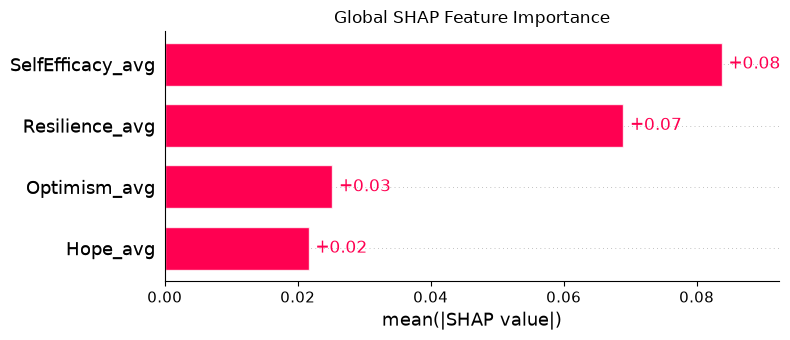

In [16]:
shap.plots.bar(
    shap_values,
    max_display=len(
        FEATURES
    ),
    show=False
)

plt.title(
    "Global SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "SHAP_Global_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SHAP beeswarm

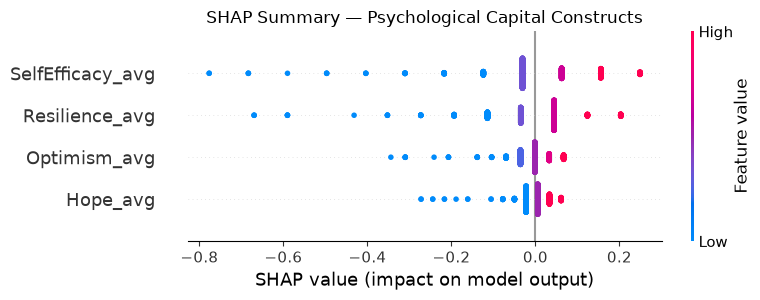

In [17]:
shap.plots.beeswarm(
    shap_values,
    max_display=len(
        FEATURES
    ),
    show=False
)

plt.title(
    "SHAP Summary — Psychological Capital Constructs"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SHAP Dependence / Scatter plots

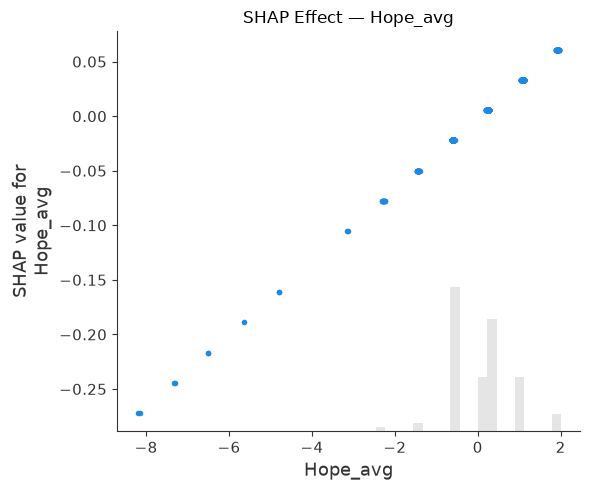

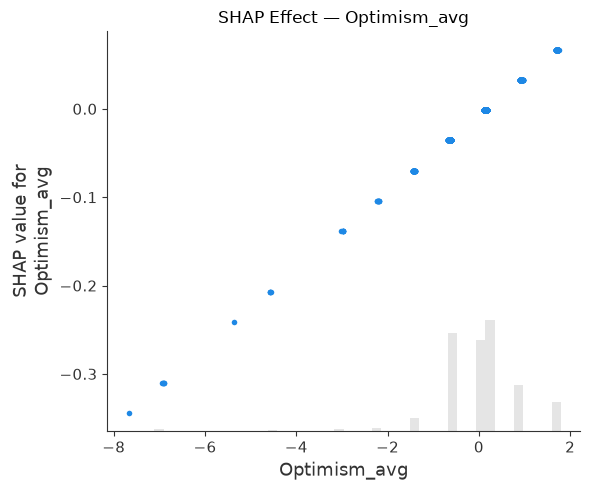

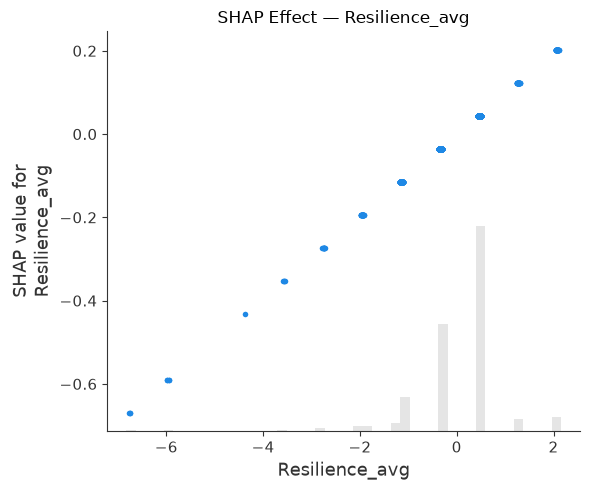

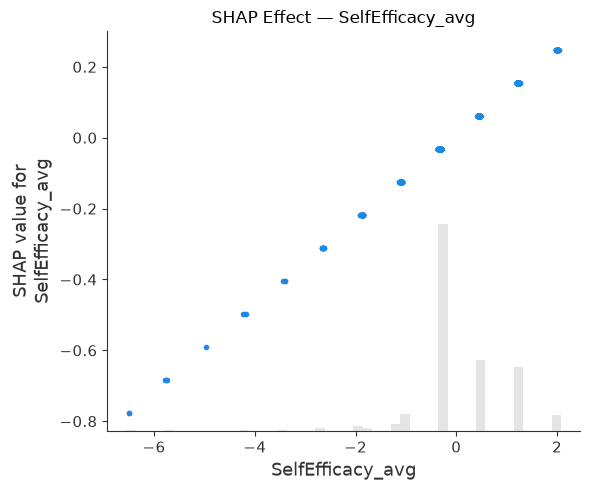

In [18]:
for feature_name in FEATURES:

    shap.plots.scatter(
        shap_values[
            :,
            feature_name
        ],
        show=False
    )

    plt.title(
        f"SHAP Effect — {feature_name}"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"SHAP_Effect_{feature_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Select representative cases

In [19]:
all_predictions = final_model.predict(
    X
)

prediction_df = pd.DataFrame({
    "Index": X.index,
    "Prediction": all_predictions
})

lowest_index = (
    prediction_df
    .sort_values(
        "Prediction"
    )
    .iloc[0][
        "Index"
    ]
)

highest_index = (
    prediction_df
    .sort_values(
        "Prediction"
    )
    .iloc[-1][
        "Index"
    ]
)

median_prediction = np.median(
    all_predictions
)

median_index = (
    np.abs(
        all_predictions
        -
        median_prediction
    )
    .argmin()
)

LOCAL_CASES = {
    "Low_Prediction": int(
        lowest_index
    ),

    "Typical_Prediction": int(
        median_index
    ),

    "High_Prediction": int(
        highest_index
    )
}

LOCAL_CASES

{'Low_Prediction': 201, 'Typical_Prediction': 28, 'High_Prediction': 994}

Create local explanation tables

In [20]:
local_explanation_rows = []

for case_name, row_index in (
    LOCAL_CASES.items()
):

    prediction = float(
        final_model.predict(
            X.loc[
                [row_index]
            ]
        )[0]
    )

    for feature_position, feature_name in enumerate(
        FEATURES
    ):

        local_explanation_rows.append({
            "Case": case_name,
            "Row_Index": row_index,
            "Prediction": prediction,
            "Feature": feature_name,
            "Original_Value": float(
                X.loc[
                    row_index,
                    feature_name
                ]
            ),
            "Scaled_Value": float(
                X_scaled.loc[
                    row_index,
                    feature_name
                ]
            ),
            "SHAP_Value": float(
                shap_values.values[
                    row_index,
                    feature_position
                ]
            )
        })


local_explanations_df = pd.DataFrame(
    local_explanation_rows
)

local_explanations_df

,Case,Row_Index,Prediction,Feature,Original_Value,Scaled_Value,SHAP_Value
0,Low_Prediction,201,2.086122,Hope_avg,1.333333,-7.321174,-0.244420
1,Low_Prediction,201,2.086122,Optimism_avg,1.333333,-6.915534,-0.309833
2,Low_Prediction,201,2.086122,Resilience_avg,1.333333,-6.774107,-0.669658
3,Low_Prediction,201,2.086122,SelfEfficacy_avg,1.333333,-6.527653,-0.776619
4,Typical_Prediction,28,4.104501,Hope_avg,4.333333,0.245496,0.005555
5,Typical_Prediction,28,4.104501,Optimism_avg,4.333333,0.145136,-0.001371
6,Typical_Prediction,28,4.104501,Resilience_avg,4.333333,0.464046,0.044432
7,Typical_Prediction,28,4.104501,SelfEfficacy_avg,4.000000,-0.324871,-0.030766
8,High_Prediction,994,4.666980,Hope_avg,5.000000,1.926979,0.061105
9,High_Prediction,994,4.666980,Optimism_avg,5.000000,1.714174,0.067176


Local waterfall plots

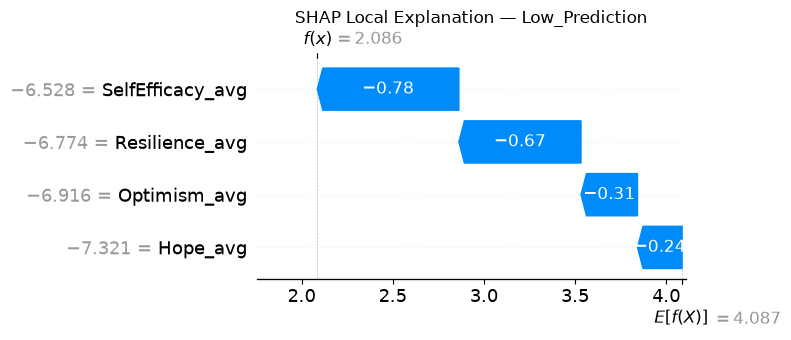

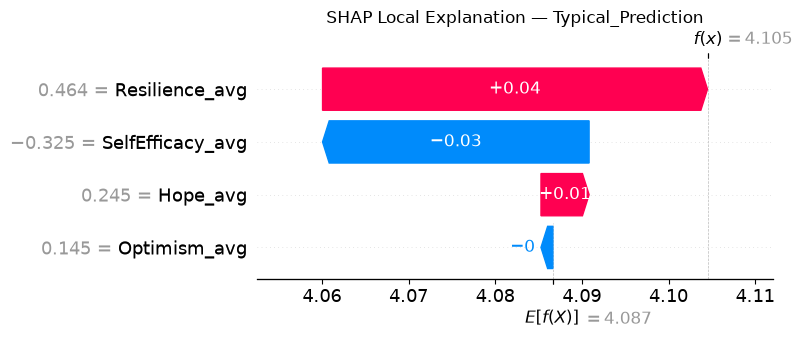

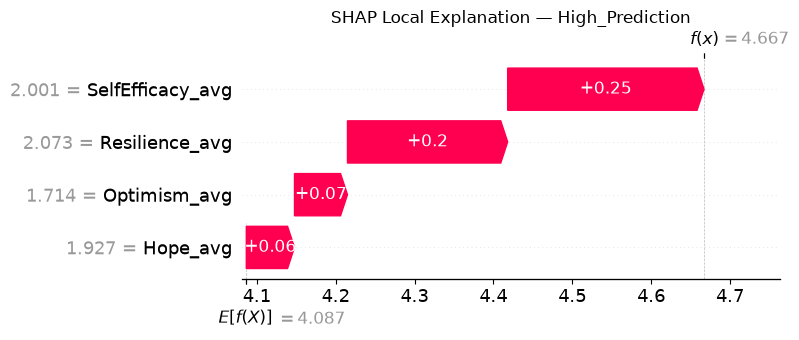

In [21]:
for case_name, row_index in (
    LOCAL_CASES.items()
):

    shap.plots.waterfall(
        shap_values[
            row_index
        ],
        max_display=len(
            FEATURES
        ),
        show=False
    )

    plt.title(
        f"SHAP Local Explanation — {case_name}"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"SHAP_Local_{case_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Verify SHAP additive property

In [22]:
shap_reconstructed_predictions = (
    shap_values.base_values
    +
    shap_values.values.sum(
        axis=1
    )
)

elasticnet_scaled_predictions = (
    elasticnet_model.predict(
        X_scaled
    )
)

shap_additivity_max_difference = np.max(
    np.abs(
        shap_reconstructed_predictions
        -
        elasticnet_scaled_predictions
    )
)

print(
    "SHAP additivity valid:",
    np.allclose(
        shap_reconstructed_predictions,
        elasticnet_scaled_predictions
    )
)

print(
    "Maximum difference:",
    shap_additivity_max_difference
)

SHAP additivity valid: True
Maximum difference: 8.881784197001252e-16


d:\internship-employability-project\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(


Permutation Importance

## Permutation Importance Robustness Check

Permutation importance model-agnostic method එකක් වන අතර feature එක random ලෙස shuffle කළ විට model performance කොපමණ අඩුවෙනවද යන්න පරීක්ෂා කරයි.

SHAP සහ model coefficients වලින් ලැබෙන feature-ranking evidence එක cross-check කිරීම සඳහා permutation importance භාවිත කරයි.

In [23]:
permutation_result = permutation_importance(
    final_model,
    X,
    y,
    scoring="r2",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": FEATURES,
    "Permutation_Importance_Mean":
        permutation_result.importances_mean,

    "Permutation_Importance_Std":
        permutation_result.importances_std
})

permutation_df = (
    permutation_df
    .sort_values(
        "Permutation_Importance_Mean",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

permutation_df[
    "Permutation_Rank"
] = np.arange(
    1,
    len(
        permutation_df
    ) + 1
)

permutation_df

,Feature,Permutation_Importance_Mean,Permutation_Importance_Std,Permutation_Rank
0,SelfEfficacy_avg,0.263940,0.012081,1
1,Resilience_avg,0.177424,0.009274,2
2,Optimism_avg,0.035567,0.004149,3
3,Hope_avg,0.020384,0.003451,4


Cross-method consistency

In [24]:
explainability_comparison = (
    shap_importance_df[
        [
            "Feature",
            "Mean_Absolute_SHAP",
            "SHAP_Rank"
        ]
    ]
    .merge(
        coefficient_df[
            [
                "Feature",
                "Coefficient",
                "Absolute_Coefficient",
                "Direction",
                "Coefficient_Rank"
            ]
        ],
        on="Feature",
        how="left"
    )
    .merge(
        permutation_df[
            [
                "Feature",
                "Permutation_Importance_Mean",
                "Permutation_Rank"
            ]
        ],
        on="Feature",
        how="left"
    )
)

explainability_comparison

,Feature,Mean_Absolute_SHAP,SHAP_Rank,Coefficient,Absolute_Coefficient,Direction,Coefficient_Rank,Permutation_Importance_Mean,Permutation_Rank
0,SelfEfficacy_avg,0.083802,1,0.120245,0.120245,Positive,1,0.263940,1
1,Resilience_avg,0.068987,2,0.098656,0.098656,Positive,2,0.177424,2
2,Optimism_avg,0.025221,3,0.043687,0.043687,Positive,3,0.035567,3
3,Hope_avg,0.021676,4,0.033036,0.033036,Positive,4,0.020384,4


Rank consistency

In [25]:
explainability_comparison[
    "SHAP_Coefficient_Rank_Difference"
] = (
    explainability_comparison[
        "SHAP_Rank"
    ]
    -
    explainability_comparison[
        "Coefficient_Rank"
    ]
).abs()

explainability_comparison[
    "SHAP_Permutation_Rank_Difference"
] = (
    explainability_comparison[
        "SHAP_Rank"
    ]
    -
    explainability_comparison[
        "Permutation_Rank"
    ]
).abs()

explainability_comparison

,Feature,Mean_Absolute_SHAP,SHAP_Rank,Coefficient,Absolute_Coefficient,Direction,Coefficient_Rank,Permutation_Importance_Mean,Permutation_Rank,SHAP_Coefficient_Rank_Difference,SHAP_Permutation_Rank_Difference
0,SelfEfficacy_avg,0.083802,1,0.120245,0.120245,Positive,1,0.263940,1,0,0
1,Resilience_avg,0.068987,2,0.098656,0.098656,Positive,2,0.177424,2,0,0
2,Optimism_avg,0.025221,3,0.043687,0.043687,Positive,3,0.035567,3,0,0
3,Hope_avg,0.021676,4,0.033036,0.033036,Positive,4,0.020384,4,0,0


Optional readable labels

In [26]:
FEATURE_LABELS = {
    "Hope_avg": "Hope",
    "Optimism_avg": "Optimism",
    "Resilience_avg": "Resilience",
    "SelfEfficacy_avg": "Self-Efficacy"
}

readable_shap_df = (
    shap_importance_df
    .copy()
)

readable_shap_df[
    "Construct"
] = (
    readable_shap_df[
        "Feature"
    ]
    .map(
        FEATURE_LABELS
    )
)

readable_shap_df[
    [
        "Construct",
        "Mean_Absolute_SHAP",
        "SHAP_Rank"
    ]
]

,Construct,Mean_Absolute_SHAP,SHAP_Rank
0,Self-Efficacy,0.083802,1
1,Resilience,0.068987,2
2,Optimism,0.025221,3
3,Hope,0.021676,4


Recommendation evidence table preparation

In [27]:
recommendation_evidence_df = (
    explainability_comparison
    .copy()
)

recommendation_evidence_df[
    "Construct"
] = (
    recommendation_evidence_df[
        "Feature"
    ]
    .map(
        FEATURE_LABELS
    )
)

recommendation_evidence_df[
    "Model_Evidence"
] = np.where(
    recommendation_evidence_df[
        "Coefficient"
    ] > 0,
    "Higher construct values are associated with higher model predictions",
    np.where(
        recommendation_evidence_df[
            "Coefficient"
        ] < 0,
        "Higher construct values are associated with lower model predictions",
        "No fitted contribution"
    )
)

recommendation_evidence_df

,Feature,Mean_Absolute_SHAP,SHAP_Rank,Coefficient,Absolute_Coefficient,Direction,Coefficient_Rank,Permutation_Importance_Mean,Permutation_Rank,SHAP_Coefficient_Rank_Difference,SHAP_Permutation_Rank_Difference,Construct,Model_Evidence
0,SelfEfficacy_avg,0.083802,1,0.120245,0.120245,Positive,1,0.263940,1,0,0,Self-Efficacy,Higher construct values are associated with hi...
1,Resilience_avg,0.068987,2,0.098656,0.098656,Positive,2,0.177424,2,0,0,Resilience,Higher construct values are associated with hi...
2,Optimism_avg,0.025221,3,0.043687,0.043687,Positive,3,0.035567,3,0,0,Optimism,Higher construct values are associated with hi...
3,Hope_avg,0.021676,4,0.033036,0.033036,Positive,4,0.020384,4,0,0,Hope,Higher construct values are associated with hi...


In [28]:
coefficient_df.to_csv(
    REPORT_DIR
    / "ElasticNet_Coefficients.csv",
    index=False
)

shap_importance_df.to_csv(
    REPORT_DIR
    / "SHAP_Global_Importance.csv",
    index=False
)

local_explanations_df.to_csv(
    REPORT_DIR
    / "SHAP_Local_Explanations.csv",
    index=False
)

permutation_df.to_csv(
    REPORT_DIR
    / "Permutation_Importance.csv",
    index=False
)

explainability_comparison.to_csv(
    REPORT_DIR
    / "Explainability_Method_Comparison.csv",
    index=False
)

recommendation_evidence_df.to_csv(
    REPORT_DIR
    / "Recommendation_Evidence_for_Step10.csv",
    index=False
)

print(
    "Step 09 explainability reports saved."
)

Step 09 explainability reports saved.


In [29]:
step09_validation = pd.DataFrame({

    "Check": [

        "Final Step 08 model artifact exists",

        "Saved model hash verified",

        "Saved model loaded without retraining",

        "Feature order verified",

        "Reference predictions reproduced",

        "Saved scaler used for transformation",

        "ElasticNet coefficients extracted",

        "SHAP values calculated",

        "SHAP global importance calculated",

        "SHAP local explanations generated",

        "SHAP additive property verified",

        "Permutation importance calculated",

        "Explainability methods compared",

        "Step 10 evidence table prepared",

        "Reports saved"
    ],

    "Status": [

        (
            "PASS"
            if MODEL_PATH.exists()
            else "FAIL"
        ),

        (
            "PASS"
            if current_model_hash
            ==
            saved_model_hash
            else "FAIL"
        ),

        "PASS",

        (
            "PASS"
            if feature_order_valid
            else "FAIL"
        ),

        (
            "PASS"
            if np.allclose(
                current_predictions,
                stored_predictions
            )
            else "FAIL"
        ),

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        (
            "PASS"
            if np.allclose(
                shap_reconstructed_predictions,
                elasticnet_scaled_predictions
            )
            else "FAIL"
        ),

        "PASS",

        "PASS",

        "PASS",

        "PASS"
    ]
})

step09_validation

,Check,Status
0,Final Step 08 model artifact exists,PASS
1,Saved model hash verified,PASS
2,Saved model loaded without retraining,PASS
3,Feature order verified,PASS
4,Reference predictions reproduced,PASS
5,Saved scaler used for transformation,PASS
6,ElasticNet coefficients extracted,PASS
7,SHAP values calculated,PASS
8,SHAP global importance calculated,PASS
9,SHAP local explanations generated,PASS


Save validation

In [30]:
step09_validation.to_csv(
    REPORT_DIR
    / "Step09_Validation.csv",
    index=False
)

Final output summary

In [31]:
print(
    "PHASE 03 — STEP 09 EXPLAINABLE AI / SHAP"
)

print(
    "\nGLOBAL SHAP IMPORTANCE:"
)

print(
    shap_importance_df
    .to_string(
        index=False
    )
)

print(
    "\nCOEFFICIENTS:"
)

print(
    coefficient_df
    .to_string(
        index=False
    )
)

print(
    "\nPERMUTATION IMPORTANCE:"
)

print(
    permutation_df
    .to_string(
        index=False
    )
)

print(
    "\nCROSS-METHOD COMPARISON:"
)

print(
    explainability_comparison
    .to_string(
        index=False
    )
)

print(
    "\nSTEP 09 VALIDATION:"
)

print(
    step09_validation
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 09 EXPLAINABLE AI / SHAP

GLOBAL SHAP IMPORTANCE:
         Feature  Mean_Absolute_SHAP  Mean_Signed_SHAP  SHAP_Rank
SelfEfficacy_avg            0.083802          0.008298          1
  Resilience_avg            0.068987         -0.001349          2
    Optimism_avg            0.025221         -0.007712          3
        Hope_avg            0.021676         -0.002555          4

COEFFICIENTS:
         Feature  Coefficient  Absolute_Coefficient Direction  Coefficient_Rank
SelfEfficacy_avg     0.120245              0.120245  Positive                 1
  Resilience_avg     0.098656              0.098656  Positive                 2
    Optimism_avg     0.043687              0.043687  Positive                 3
        Hope_avg     0.033036              0.033036  Positive                 4

PERMUTATION IMPORTANCE:
         Feature  Permutation_Importance_Mean  Permutation_Importance_Std  Permutation_Rank
SelfEfficacy_avg                     0.263940                    0.01208

## Step 09 අවසාන නිගමනය

Step 08 එකේ save කරන ලද exact ElasticNet pipeline එක retrain නොකර Explainable AI analysis සඳහා භාවිත කරන ලදී.

Final model artifact hash, feature order සහ saved reference predictions verify කිරීමෙන් explainability analysis එක exact frozen model behaviour එක මත පදනම් වන බව තහවුරු කරන ලදී.

SHAP analysis මගින් Psychological Capital constructs model predictions සඳහා ලබාදෙන global සහ individual contributions quantify කරන ලදී.

ElasticNet standardized coefficients මගින් feature contribution direction සහ relative magnitude පරීක්ෂා කරන ලදී.

Permutation importance model-agnostic robustness check එකක් ලෙස භාවිත කර SHAP සහ coefficient-based importance evidence cross-check කරන ලදී.

SHAP explanations model prediction behaviour නිරූපණය කරන අතර causal relationships prove නොකරයි.

මෙම explainability evidence Step 10 recommendation system එකේ evidence-grounded guidance සඳහා භාවිත කරනු ලබයි.

## Normalized SHAP Importance

Global SHAP importance values normalized කර percentage representation එකක් සකස් කරයි.

මෙය features අතර relative model reliance වඩාත් පැහැදිලිව communicate කිරීමට භාවිත කරයි.

මෙම percentages causal contribution ලෙස interpret නොකරන අතර model-relative importance ලෙස පමණක් සලකයි.

In [32]:
shap_importance_percentage_df = (
    shap_importance_df
    .copy()
)

total_shap_importance = (
    shap_importance_percentage_df[
        "Mean_Absolute_SHAP"
    ].sum()
)

shap_importance_percentage_df[
    "Relative_SHAP_Percent"
] = (
    shap_importance_percentage_df[
        "Mean_Absolute_SHAP"
    ]
    /
    total_shap_importance
    *
    100
)

shap_importance_percentage_df

,Feature,Mean_Absolute_SHAP,Mean_Signed_SHAP,SHAP_Rank,Relative_SHAP_Percent
0,SelfEfficacy_avg,0.083802,0.008298,1,41.966880
1,Resilience_avg,0.068987,-0.001349,2,34.547883
2,Optimism_avg,0.025221,-0.007712,3,12.630413
3,Hope_avg,0.021676,-0.002555,4,10.854824


## Bootstrap Stability of Global SHAP Importance

Global SHAP feature-importance ranking එක sample variation හේතුවෙන් substantially වෙනස් වෙනවද යන්න bootstrap resampling මගින් පරීක්ෂා කරයි.

Final fitted model එක retrain නොකර existing SHAP values rows resample කර mean absolute SHAP importance නැවත calculate කරයි.

මෙම analysis එක explainability stability සහ ranking robustness evaluate කිරීමට භාවිත කරයි.

In [33]:
rng = np.random.default_rng(
    42
)

N_BOOTSTRAP = 2000

bootstrap_shap_results = {
    feature: []
    for feature in FEATURES
}

shap_matrix = (
    shap_values.values
)

n_rows = shap_matrix.shape[0]

for _ in range(N_BOOTSTRAP):

    sample_indices = rng.choice(
        n_rows,
        size=n_rows,
        replace=True
    )

    sample_shap = (
        shap_matrix[
            sample_indices
        ]
    )

    sample_importance = (
        np.abs(
            sample_shap
        )
        .mean(
            axis=0
        )
    )

    for feature_index, feature_name in enumerate(
        FEATURES
    ):

        bootstrap_shap_results[
            feature_name
        ].append(
            sample_importance[
                feature_index
            ]
        )

In [34]:
bootstrap_shap_summary_rows = []

for feature_name in FEATURES:

    values = np.array(
        bootstrap_shap_results[
            feature_name
        ]
    )

    bootstrap_shap_summary_rows.append({

        "Feature":
            feature_name,

        "Bootstrap_Mean_SHAP":
            values.mean(),

        "Bootstrap_Std_SHAP":
            values.std(),

        "CI_95_Lower":
            np.percentile(
                values,
                2.5
            ),

        "CI_95_Upper":
            np.percentile(
                values,
                97.5
            )
    })


bootstrap_shap_summary_df = (
    pd.DataFrame(
        bootstrap_shap_summary_rows
    )
    .sort_values(
        "Bootstrap_Mean_SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

bootstrap_shap_summary_df[
    "Bootstrap_Rank"
] = np.arange(
    1,
    len(
        bootstrap_shap_summary_df
    ) + 1
)

bootstrap_shap_summary_df

,Feature,Bootstrap_Mean_SHAP,Bootstrap_Std_SHAP,CI_95_Lower,CI_95_Upper,Bootstrap_Rank
0,SelfEfficacy_avg,0.083777,0.002683,0.078625,0.089143,1
1,Resilience_avg,0.068964,0.002201,0.064820,0.073510,2
2,Optimism_avg,0.025219,0.001137,0.023098,0.027528,3
3,Hope_avg,0.021683,0.000788,0.020176,0.023287,4


## Cross-Method Rank Agreement

SHAP, model coefficients සහ permutation importance methods අතර feature-ranking consistency quantitatively evaluate කරයි.

High rank correlation values ලැබීම independent explainability approaches similar model-importance ordering එකක් identify කරන බව පෙන්වයි.

In [35]:
from scipy.stats import (
    spearmanr,
    kendalltau
)

In [36]:
shap_ranks = (
    explainability_comparison[
        "SHAP_Rank"
    ]
)

coefficient_ranks = (
    explainability_comparison[
        "Coefficient_Rank"
    ]
)

permutation_ranks = (
    explainability_comparison[
        "Permutation_Rank"
    ]
)


rank_agreement_rows = []


comparisons = [
    (
        "SHAP vs Coefficient",
        shap_ranks,
        coefficient_ranks
    ),

    (
        "SHAP vs Permutation",
        shap_ranks,
        permutation_ranks
    ),

    (
        "Coefficient vs Permutation",
        coefficient_ranks,
        permutation_ranks
    )
]


for name, first_ranks, second_ranks in comparisons:

    spearman_rho, spearman_p = (
        spearmanr(
            first_ranks,
            second_ranks
        )
    )

    kendall_tau, kendall_p = (
        kendalltau(
            first_ranks,
            second_ranks
        )
    )

    rank_agreement_rows.append({

        "Comparison":
            name,

        "Spearman_Rho":
            spearman_rho,

        "Spearman_P":
            spearman_p,

        "Kendall_Tau":
            kendall_tau,

        "Kendall_P":
            kendall_p
    })


rank_agreement_df = pd.DataFrame(
    rank_agreement_rows
)

rank_agreement_df

,Comparison,Spearman_Rho,Spearman_P,Kendall_Tau,Kendall_P
0,SHAP vs Coefficient,1.0,0.0,1.0,0.083333
1,SHAP vs Permutation,1.0,0.0,1.0,0.083333
2,Coefficient vs Permutation,1.0,0.0,1.0,0.083333


In [37]:
prediction_series = pd.Series(
    all_predictions,
    index=X.index
)

prediction_quantiles = {
    "Low_Representative": 0.10,
    "Typical_Representative": 0.50,
    "High_Representative": 0.90
}


representative_cases = {}

for case_name, quantile_value in (
    prediction_quantiles.items()
):

    target_prediction = (
        prediction_series.quantile(
            quantile_value
        )
    )

    closest_index = (
        (
            prediction_series
            -
            target_prediction
        )
        .abs()
        .idxmin()
    )

    representative_cases[
        case_name
    ] = int(
        closest_index
    )


representative_cases

{'Low_Representative': 48,
 'Typical_Representative': 28,
 'High_Representative': 126}

In [38]:
representative_local_rows = []

for case_name, row_index in (
    representative_cases.items()
):

    prediction = float(
        final_model.predict(
            X.loc[
                [row_index]
            ]
        )[0]
    )

    for position, feature_name in enumerate(
        FEATURES
    ):

        representative_local_rows.append({

            "Case":
                case_name,

            "Row_Index":
                row_index,

            "Prediction":
                prediction,

            "Feature":
                feature_name,

            "Original_Value":
                float(
                    X.loc[
                        row_index,
                        feature_name
                    ]
                ),

            "SHAP_Value":
                float(
                    shap_values.values[
                        row_index,
                        position
                    ]
                )
        })


representative_local_df = pd.DataFrame(
    representative_local_rows
)

representative_local_df

,Case,Row_Index,Prediction,Feature,Original_Value,SHAP_Value
0,Low_Representative,48,3.883766,Hope_avg,4.000000,-0.022220
1,Low_Representative,48,3.883766,Optimism_avg,4.000000,-0.035644
2,Low_Representative,48,3.883766,Resilience_avg,3.666667,-0.114254
3,Low_Representative,48,3.883766,SelfEfficacy_avg,4.000000,-0.030766
4,Typical_Representative,28,4.104501,Hope_avg,4.333333,0.005555
5,Typical_Representative,28,4.104501,Optimism_avg,4.333333,-0.001371
6,Typical_Representative,28,4.104501,Resilience_avg,4.333333,0.044432
7,Typical_Representative,28,4.104501,SelfEfficacy_avg,4.000000,-0.030766
8,High_Representative,126,4.353013,Hope_avg,4.666667,0.033330
9,High_Representative,126,4.353013,Optimism_avg,4.666667,0.032903


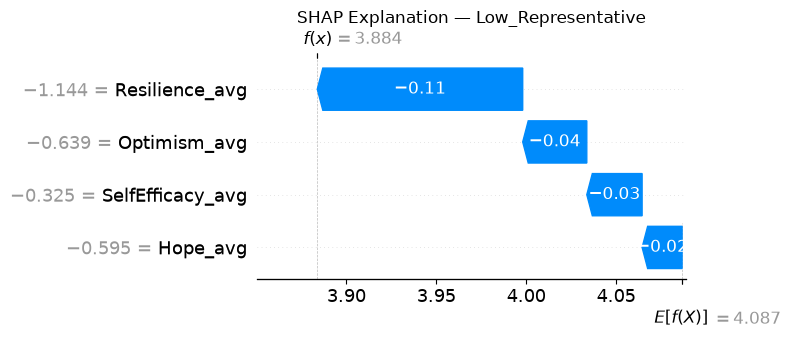

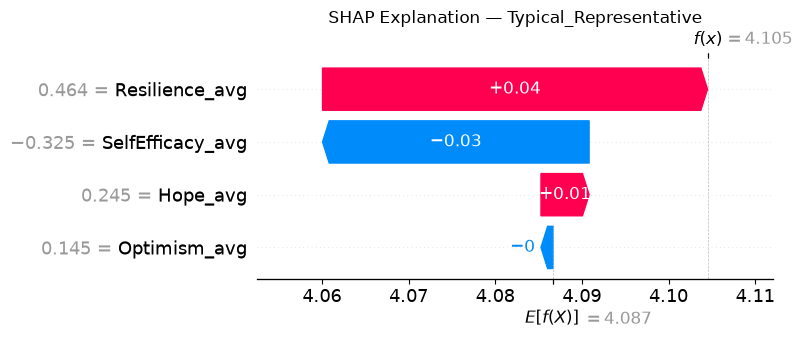

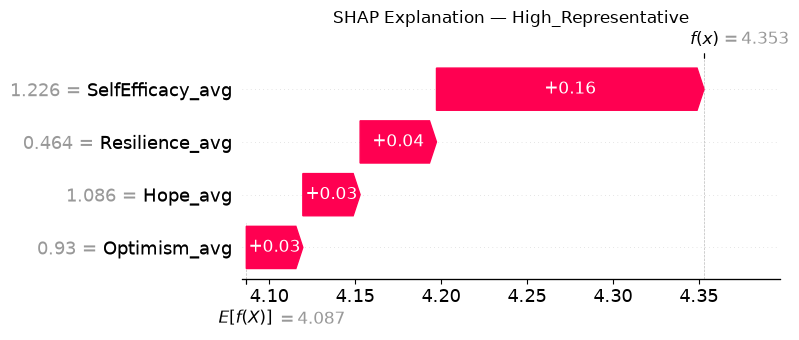

In [39]:
for case_name, row_index in (
    representative_cases.items()
):

    shap.plots.waterfall(
        shap_values[
            row_index
        ],
        max_display=len(
            FEATURES
        ),
        show=False
    )

    plt.title(
        f"SHAP Explanation — {case_name}"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"SHAP_Representative_{case_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Add feature-value vs SHAP-direction consistency

In [40]:
direction_consistency_rows = []

for i, feature_name in enumerate(
    FEATURES
):

    correlation = np.corrcoef(
        X[
            feature_name
        ],
        shap_values.values[
            :,
            i
        ]
    )[0, 1]

    direction_consistency_rows.append({

        "Feature":
            feature_name,

        "Coefficient":
            float(
                elasticnet_model.coef_[
                    i
                ]
            ),

        "Feature_SHAP_Correlation":
            correlation,

        "Direction_Consistent":
            (
                "YES"
                if (
                    elasticnet_model.coef_[i] > 0
                    and correlation > 0
                )
                or
                (
                    elasticnet_model.coef_[i] < 0
                    and correlation < 0
                )
                else
                "REVIEW"
            )
    })


direction_consistency_df = pd.DataFrame(
    direction_consistency_rows
)

direction_consistency_df

,Feature,Coefficient,Feature_SHAP_Correlation,Direction_Consistent
0,Hope_avg,0.033036,1.0,YES
1,Optimism_avg,0.043687,1.0,YES
2,Resilience_avg,0.098656,1.0,YES
3,SelfEfficacy_avg,0.120245,1.0,YES


In [41]:
shap_importance_percentage_df.to_csv(
    REPORT_DIR
    / "SHAP_Normalized_Importance.csv",
    index=False
)

bootstrap_shap_summary_df.to_csv(
    REPORT_DIR
    / "SHAP_Bootstrap_Stability.csv",
    index=False
)

rank_agreement_df.to_csv(
    REPORT_DIR
    / "Explainability_Rank_Agreement.csv",
    index=False
)

representative_local_df.to_csv(
    REPORT_DIR
    / "SHAP_Representative_Local_Explanations.csv",
    index=False
)

direction_consistency_df.to_csv(
    REPORT_DIR
    / "SHAP_Direction_Consistency.csv",
    index=False
)

print(
    "Strengthened Step 09 reports saved."
)

Strengthened Step 09 reports saved.


In [42]:
step09_strengthening_validation = pd.DataFrame({
    "Check": [
        "Normalized SHAP importance calculated",
        "Bootstrap SHAP stability evaluated",
        "Cross-method rank agreement evaluated",
        "Representative local cases evaluated",
        "Feature-SHAP direction consistency evaluated"
    ],

    "Status": [
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS"
    ]
})

step09_strengthening_validation

,Check,Status
0,Normalized SHAP importance calculated,PASS
1,Bootstrap SHAP stability evaluated,PASS
2,Cross-method rank agreement evaluated,PASS
3,Representative local cases evaluated,PASS
4,Feature-SHAP direction consistency evaluated,PASS
